In [37]:
import numpy as np
import os
import matplotlib.pyplot as plt
import json

from utils import graphics

graphics.set_matplotlib_settings()

In [ ]:
sd_card_name = "card_test"

# one entry per laser/shutter; the key is the file prefix led_driver.ino loads from the SD card
# plotting_color can be any matplotlib color, e.g. "blue" or "#2a78d6"
# each channel can have several schedules (blocks of stims); they must not overlap
channels = {
    "led0": {
        "plotting_color": "red",
        "schedules": [
            {
                "start_time": 200,
                "stim_duration": 10, # 50ms period for 20Hz
                "off_duration": 40,
                "total_stims": 5, # 20Hz
            },
            {
                "start_time": 1000,
                "stim_duration": 10, # 50ms period for 20Hz
                "off_duration": 40,
                "total_stims": 5, # 20Hz
            },
        ],
    },
    "led1": {
        "plotting_color": "blue",
        "schedules": [
            {
                "start_time": 100,
                "stim_duration": 4,
                "off_duration": 12,
                "total_stims": 150,
            },
        ],
    },
    "led2": {
        "plotting_color": "lightblue", # control 405nm
        "schedules": [
            {
                "start_time": 108,
                "stim_duration": 4,
                "off_duration": 12,
                "total_stims": 150,
            },
        ],
    },
    "shutter": {
        "plotting_color": "gray",
        "schedules": [
            {
                "start_time": 180,
                "stim_duration": 250,
                "off_duration": 1,
                "total_stims": 1,
            },
        ],
    },
}

In [39]:
event_arrays = {}
for channel_name, channel in channels.items():
    event_timesteps = [0] # first event is always off for everything at 0ms
    event_settings = [0]
    previous_schedule_end = None
    for schedule in sorted(channel["schedules"], key=lambda schedule: schedule["start_time"]):
        assert previous_schedule_end is None or schedule["start_time"] > previous_schedule_end, f"{channel_name}: Schedule starting at {schedule['start_time']}ms overlaps the previous schedule, which ends at {previous_schedule_end}ms."
        for i in range(schedule["total_stims"]):
            stim_start_time = schedule["start_time"] + i * (schedule["stim_duration"] + schedule["off_duration"])
            event_timesteps += [stim_start_time, stim_start_time + schedule["stim_duration"]]
            event_settings += [1, 0]
        previous_schedule_end = event_timesteps[-1]

    stimulus_event_timesteps = np.array(event_timesteps, dtype=np.uint32)
    stimulus_event_timesteps = np.insert(stimulus_event_timesteps, 0, len(stimulus_event_timesteps))  # first element is the size of the array
    stimulus_event_settings = np.array(event_settings, dtype=np.uint32)
    stimulus_event_settings = np.insert(stimulus_event_settings, 0, len(stimulus_event_settings))  # first element is the size of the array
    event_arrays[channel_name] = (stimulus_event_timesteps, stimulus_event_settings)

In [40]:
MAX_EVENTS = 500 # must match MAX_EVENTS in led_driver.ino

for channel_name, (stimulus_event_timesteps, stimulus_event_settings) in event_arrays.items():
    assert len(stimulus_event_timesteps) == len(stimulus_event_settings), f"{channel_name}: The two arrays must have the same length."
    assert stimulus_event_timesteps.dtype == np.uint32, f"{channel_name}: Timesteps must be integers."
    assert stimulus_event_settings.dtype == np.uint32, f"{channel_name}: Settings must be integers."
    assert np.min(stimulus_event_settings) >= 0, f"{channel_name}: Settings must be non-negative."
    assert np.max(stimulus_event_settings[1:]) <= 1, f"{channel_name}: Settings must be less than or equal to 1."
    assert np.min(stimulus_event_timesteps) >= 0, f"{channel_name}: Timesteps must be non-negative."
    assert np.max(stimulus_event_timesteps) <= 10000, f"{channel_name}: Timesteps must be less than or equal to 10000 (ms in 10s)."
    assert stimulus_event_timesteps[0] <= MAX_EVENTS, f"{channel_name}: {stimulus_event_timesteps[0]} events, but led_driver.ino only holds MAX_EVENTS = {MAX_EVENTS}."

In [41]:
os.makedirs(f"./arduino_sd_cards/{sd_card_name}", exist_ok=True)

for channel_name, (stimulus_event_timesteps, stimulus_event_settings) in event_arrays.items():
    with open(f"./arduino_sd_cards/{sd_card_name}/{channel_name}_event_timesteps.txt", "w", newline="\n") as f:
        f.write("\n".join(str(x) for x in stimulus_event_timesteps))
        f.write("\n")

    with open(f"./arduino_sd_cards/{sd_card_name}/{channel_name}_event_settings.txt", "w", newline="\n") as f:
        f.write("\n".join(str(x) for x in stimulus_event_settings))
        f.write("\n")

In [42]:
for channel_name, (stimulus_event_timesteps, stimulus_event_settings) in event_arrays.items():
    print(channel_name, len(stimulus_event_timesteps))

led0 22
led1 302
led2 302
shutter 4


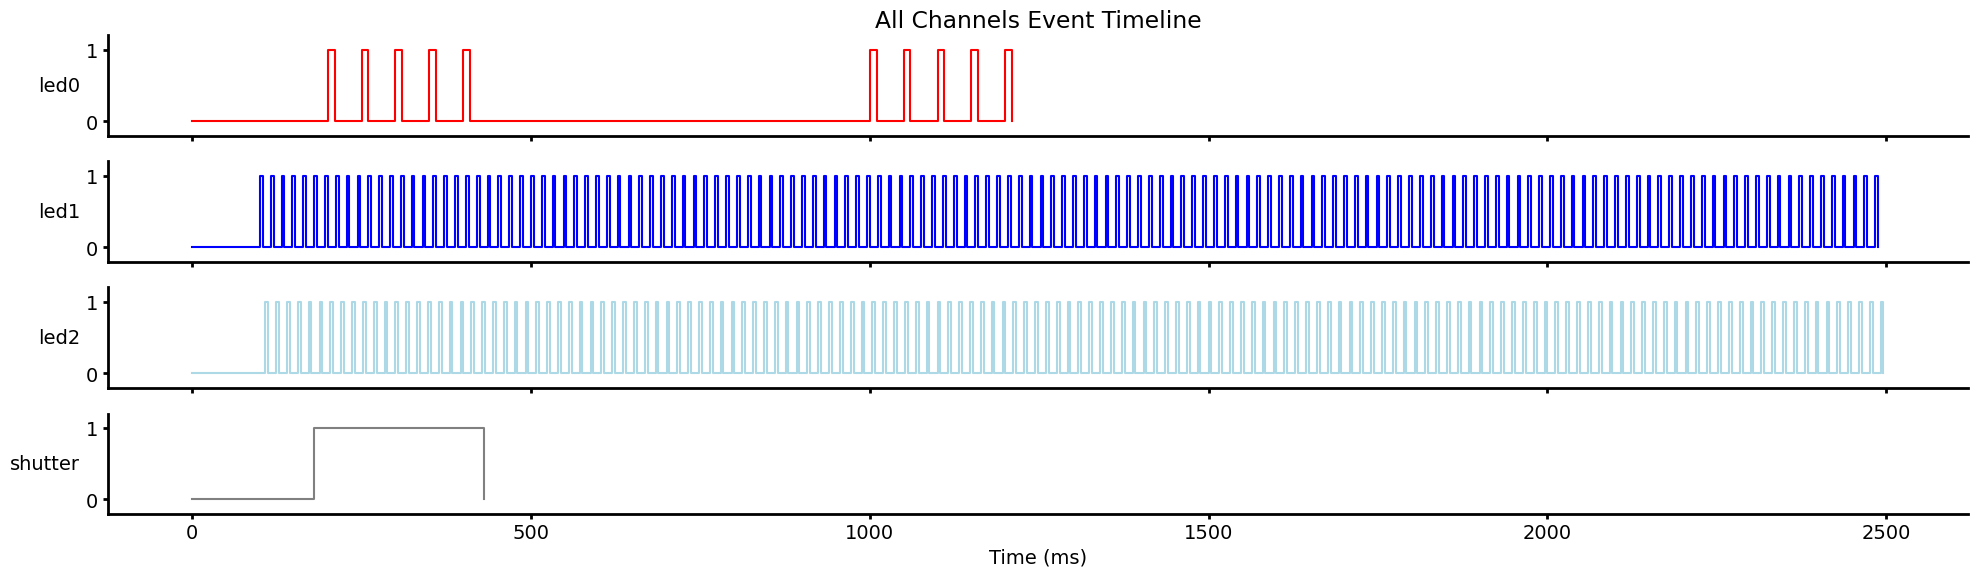

In [43]:
fig, axes = plt.subplots(len(event_arrays), 1, figsize=(20, 1.5 * len(event_arrays)), sharex=True, squeeze=False)
axes = axes[:, 0]
for ax, (channel_name, (stimulus_event_timesteps, stimulus_event_settings)) in zip(axes, event_arrays.items()):
    ax.step(stimulus_event_timesteps[1:], stimulus_event_settings[1:], where='post', color=channels[channel_name]["plotting_color"])
    ax.set_ylim(-0.2, 1.2)
    ax.set_yticks([0, 1])
    ax.set_ylabel(channel_name, rotation=0, ha='right', va='center')
axes[-1].set_xlabel('Time (ms)')
axes[0].set_title("All Channels Event Timeline")
plt.savefig(f"./arduino_sd_cards/{sd_card_name}/all_channels_timeline.png", bbox_inches='tight')
plt.show()

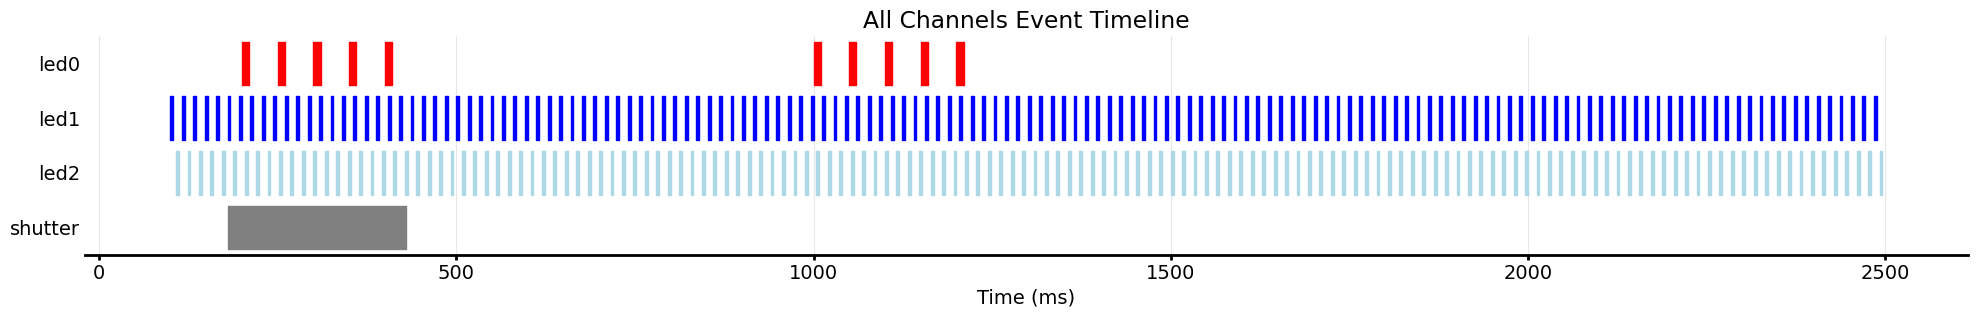

In [44]:
fig, ax = plt.subplots(figsize=(20, 0.6 * len(event_arrays) + 1))
for row, (channel_name, (stimulus_event_timesteps, stimulus_event_settings)) in enumerate(event_arrays.items()):
    timesteps = stimulus_event_timesteps[1:].astype(np.int64)
    settings = stimulus_event_settings[1:]
    end_times = np.append(timesteps[1:], timesteps[-1])
    on_intervals = [(start, end - start) for start, end, setting in zip(timesteps, end_times, settings) if setting == 1]
    ax.broken_barh(on_intervals, (row - 0.4, 0.8), color=channels[channel_name]["plotting_color"])
ax.set_yticks(range(len(event_arrays)))
ax.set_yticklabels(event_arrays.keys())
ax.set_ylim(len(event_arrays) - 0.5, -0.5) # first channel on top
ax.tick_params(axis='y', length=0)
ax.spines['left'].set_visible(False)
ax.grid(axis='x', alpha=0.3)
ax.set_axisbelow(True)
ax.set_xlabel('Time (ms)')
ax.set_title("All Channels Event Timeline")
plt.savefig(f"./arduino_sd_cards/{sd_card_name}/all_channels_timeline_gantt.png", bbox_inches='tight')
plt.show()

In [45]:
for channel_name, channel in channels.items():
    generation_params_dict = {
        "event_timesteps_filename": f"{channel_name}_event_timesteps",
        "event_settings_filename": f"{channel_name}_event_settings",
        **channel,
    }
    print(generation_params_dict)
    with open(f"./arduino_sd_cards/{sd_card_name}/{channel_name}_generation_params.json", "w") as file:
        json.dump(generation_params_dict, file)

{'event_timesteps_filename': 'led0_event_timesteps', 'event_settings_filename': 'led0_event_settings', 'plotting_color': 'red', 'schedules': [{'start_time': 200, 'stim_duration': 10, 'off_duration': 40, 'total_stims': 5}, {'start_time': 1000, 'stim_duration': 10, 'off_duration': 40, 'total_stims': 5}]}
{'event_timesteps_filename': 'led1_event_timesteps', 'event_settings_filename': 'led1_event_settings', 'plotting_color': 'blue', 'schedules': [{'start_time': 100, 'stim_duration': 4, 'off_duration': 12, 'total_stims': 150}]}
{'event_timesteps_filename': 'led2_event_timesteps', 'event_settings_filename': 'led2_event_settings', 'plotting_color': 'lightblue', 'schedules': [{'start_time': 108, 'stim_duration': 4, 'off_duration': 12, 'total_stims': 150}]}
{'event_timesteps_filename': 'shutter_event_timesteps', 'event_settings_filename': 'shutter_event_settings', 'plotting_color': 'gray', 'schedules': [{'start_time': 180, 'stim_duration': 250, 'off_duration': 1, 'total_stims': 1}]}
